In [5]:
Notre modèle utilise 187 valeurs par ECG pour effectuer sa classification.

Nous voulons savoir quelles positions du signal ont le plus influencé les décisions du modèle

In [6]:
normal = pd.read_csv("../data/ptbdb_normal.csv", header=None)
abnormal = pd.read_csv("../data/ptbdb_abnormal.csv", header=None)

In [10]:
print("normal :", normal.shape)
print("abnormal :", abnormal.shape)

normal : (4046, 188)
abnormal : (10506, 188)


In [11]:
normal.head()

,0,1,2,3,4,5,6,7,8,9,...,178,179,180,181,182,183,184,185,186,187
0,1.000000,0.900324,0.358590,0.051459,0.046596,0.126823,0.133306,0.119125,0.110616,0.113047,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.000000,0.794681,0.375387,0.116883,0.000000,0.171923,0.283859,0.293754,0.325912,0.345083,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.909029,0.791482,0.423169,0.186712,0.000000,0.007836,0.063032,0.077002,0.074957,0.077342,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.000000,0.478893,0.056760,0.064176,0.081289,0.072732,0.055619,0.048774,0.054478,0.041643,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.000000,0.867238,0.201360,0.099349,0.141336,0.120934,0.108516,0.096393,0.093436,0.100828,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [12]:
print("Classes normales :")
print(normal.iloc[:, -1].value_counts())

Classes normales :
187
0.0    4046
Name: count, dtype: int64


In [13]:
print("Classes anormales :")
print(abnormal.iloc[:, -1].value_counts())

Classes anormales :
187
1.0    10506
Name: count, dtype: int64


In [14]:
print(abnormal.iloc[:, -1])

0        1.0
1        1.0
2        1.0
3        1.0
4        1.0
        ... 
10501    1.0
10502    1.0
10503    1.0
10504    1.0
10505    1.0
Name: 187, Length: 10506, dtype: float64


In [15]:
print(abnormal.iloc[:, :].value_counts())

0         1         2         3         4         5         6         7         8         9         10        11        12        13        14        15        16        17        18        19        20        21        22        23        24        25        26        27        28        29        30        31        32        33        34        35        36        37        38        39        40        41        42        43        44        45        46        47        48        49        50        51        52        53        54        55        56        57        58        59        60        61        62        63        64        65        66        67        68        69        70        71        72        73        74        75        76        77        78        79        80        81        82        83        84        85        86        87        88        89        90        91        92        93        94        95        96        97        98        99        

In [16]:
df = pd.concat([normal,abnormal],ignore_index=True)

In [17]:
df

,0,1,2,3,4,5,6,7,8,9,...,178,179,180,181,182,183,184,185,186,187
0,1.000000,0.900324,0.358590,0.051459,0.046596,0.126823,0.133306,0.119125,0.110616,0.113047,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.000000,0.794681,0.375387,0.116883,0.000000,0.171923,0.283859,0.293754,0.325912,0.345083,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.909029,0.791482,0.423169,0.186712,0.000000,0.007836,0.063032,0.077002,0.074957,0.077342,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.000000,0.478893,0.056760,0.064176,0.081289,0.072732,0.055619,0.048774,0.054478,0.041643,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.000000,0.867238,0.201360,0.099349,0.141336,0.120934,0.108516,0.096393,0.093436,0.100828,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14547,0.981409,1.000000,0.559171,0.287093,0.196639,0.204862,0.215946,0.243833,0.242760,0.250268,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
14548,0.906250,0.922379,0.878024,0.810484,0.712702,0.667339,0.608871,0.527218,0.480847,0.442540,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
14549,1.000000,0.867971,0.674122,0.470332,0.296987,0.169307,0.077664,0.081392,0.074868,0.089779,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
14550,1.000000,0.984672,0.658888,0.556394,0.446809,0.395790,0.315260,0.276367,0.261039,0.258522,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [18]:
print(df.iloc[:, -1].value_counts())

187
1.0    10506
0.0     4046
Name: count, dtype: int64


Maintenant on va esseyer D'afficher un battement

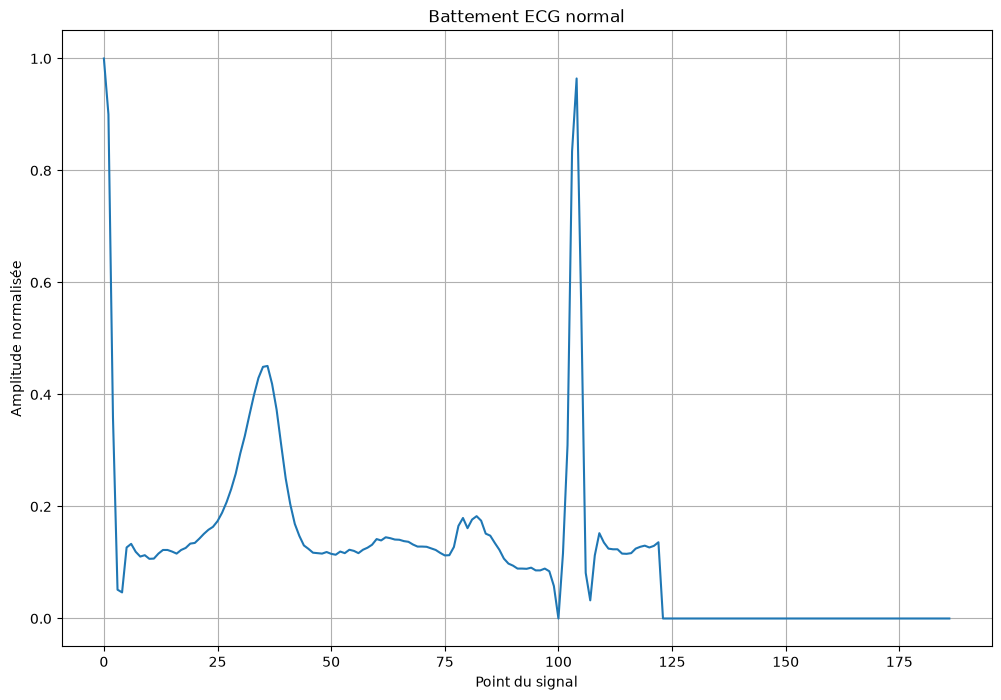

In [25]:
signal = normal.iloc[0, :-1]

plt.figure(figsize=(12,8))
plt.plot(signal.values)
plt.title("Battement ECG normal")
plt.xlabel("Point du signal")
plt.ylabel("Amplitude normalisée")
plt.grid(True)
plt.show()

On va afficher deux battements cardiaques sur le même graphique, un normal et un anormal.

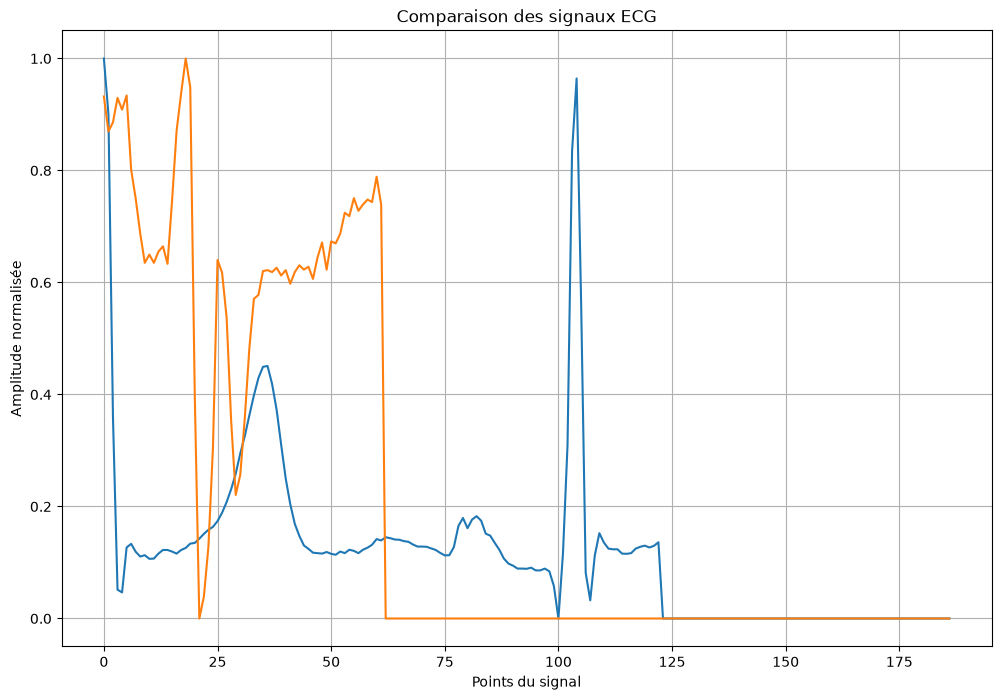

In [29]:
signal_normal = normal.iloc[0, :-1]
signal_abnormal = abnormal.iloc[0, :-1]
plt.figure(figsize=(12,8))
plt.plot(signal_normal.values, label="normal")
plt.plot(signal_abnormal.values,label="abnormal")

plt.title("Comparaison des signaux ECG")
plt.xlabel("Points du signal")
plt.ylabel("Amplitude normalisée")

plt.grid(True)
plt.show()


In [31]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14552 entries, 0 to 14551
Columns: 188 entries, 0 to 187
dtypes: float64(188)
memory usage: 20.9 MB


In [36]:
df.isnull().sum().sum()

np.int64(0)

In [37]:
print(df.iloc[:, -1].value_counts())

187
1.0    10506
0.0     4046
Name: count, dtype: int64


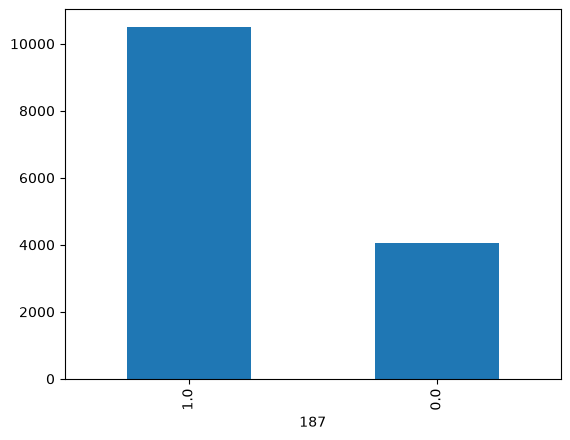

In [38]:
df.iloc[:, -1].value_counts().plot(kind="bar")
plt.show()

In [40]:
df.iloc[: , -1].value_counts(normalize=True)*100

187
1.0    72.196262
0.0    27.803738
Name: proportion, dtype: float64

In [41]:
x = df.iloc[:,:-1]
y = df.iloc[:, -1]

In [48]:
print(x.shape)
print(y.shape)

(14552, 187)
(14552,)


on ve esseyer de calculer la corrélation entre deux points du signal, observés sur tous les battements ECG

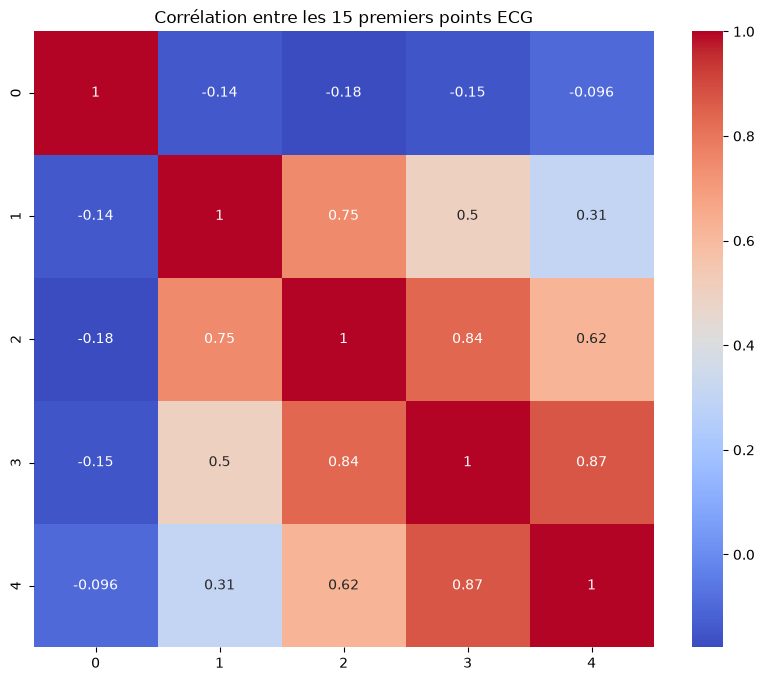

In [49]:
correlation  =x.iloc[:,:5].corr()
plt.figure(figsize=(10,8))
sns.heatmap(correlation,annot=True,cmap="coolwarm")
plt.title("Corrélation entre les 15 premiers points ECG")
plt.show()

Esseyons  de comparer deux signaux ECG complet

In [56]:
signal_normal = normal.iloc[0, : -1]
signal_abnormal=abnormal.iloc[0, :-1]
signal_normal.corr(signal_abnormal)



np.float64(0.36481781527493135)

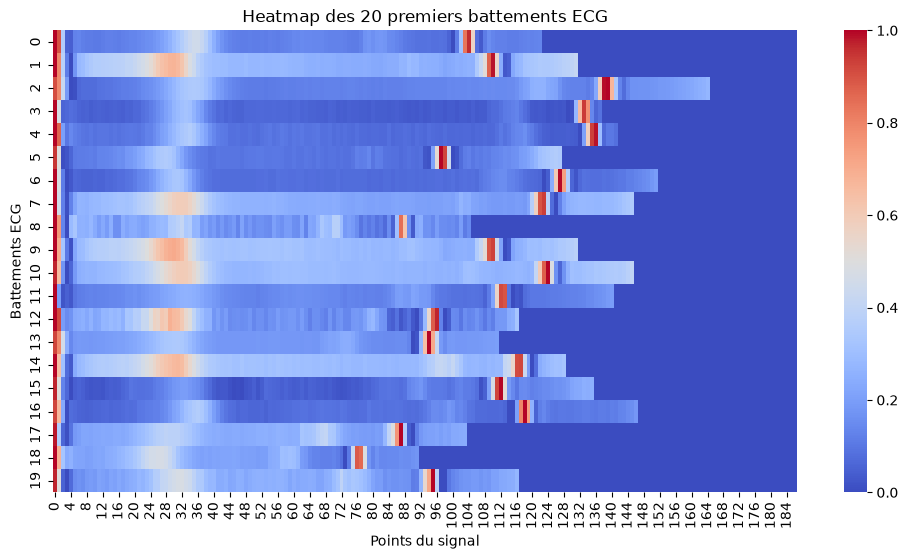

In [57]:
plt.figure(figsize=(12, 6))

sns.heatmap(x.iloc[:20, :], cmap="coolwarm")

plt.title("Heatmap des 20 premiers battements ECG")
plt.xlabel("Points du signal")
plt.ylabel("Battements ECG")
plt.show()

Pour chercher a bien comprendre on va esseyer de comparer la moyenne de tous les battements de chaque classe au lieu de juste comparer un ESg normal avec ESG anormal

In [58]:
moyenne_normal = normal.iloc[:, :-1].mean()
moyenne_anormal = abnormal.iloc[:, :-1].mean()

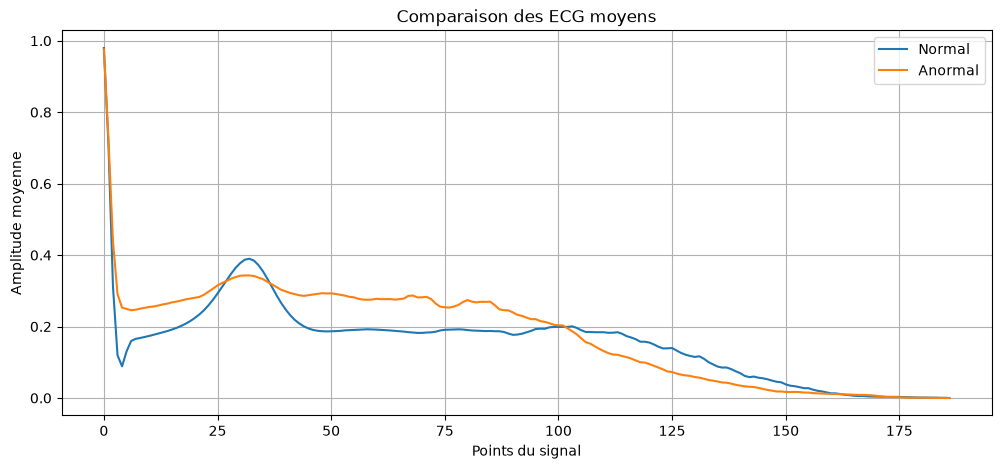

In [59]:
plt.figure(figsize=(12, 5))

plt.plot(moyenne_normal.values, label="Normal")
plt.plot(moyenne_anormal.values, label="Anormal")

plt.title("Comparaison des ECG moyens")
plt.xlabel("Points du signal")
plt.ylabel("Amplitude moyenne")
plt.legend()
plt.grid(True)
plt.show()

Première observation : les profils moyens sont différents.

Cela suggère que certaines positions du signal contiennent des informations potentiellement utiles pour distinguer les deux classes.

Deuxième observation : les écarts dépendent de la position.

Par exemple, autour du point 60, la courbe anormale est sensiblement au-dessus de la courbe normale. En revanche, autour du point 100, elles se rejoignent.

Troisième observation : les deux courbes se rapprochent de zéro à la fin.

Les dernières positions semblent contenir peu de différences entre les moyennes des classes. Mais cela ne prouve pas que ces caractéristiques sont inutiles.

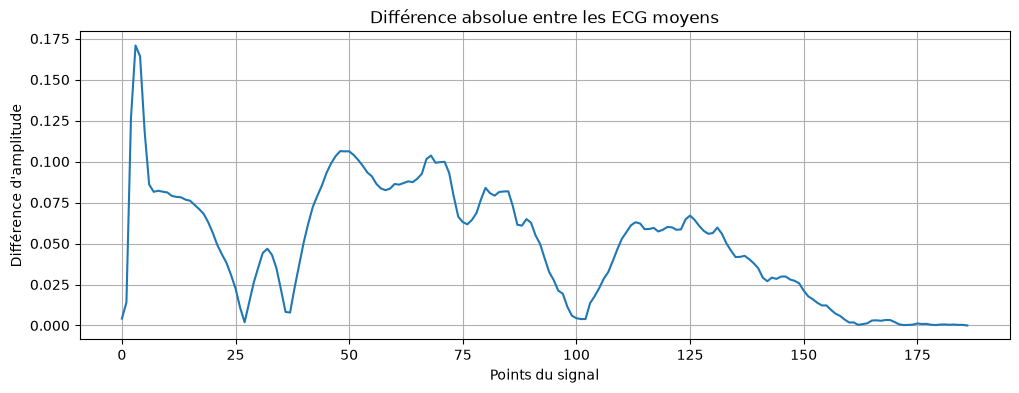

In [60]:
difference = abs(moyenne_normal - moyenne_anormal)

plt.figure(figsize=(12, 4))
plt.plot(difference.values)

plt.title("Différence absolue entre les ECG moyens")
plt.xlabel("Points du signal")
plt.ylabel("Différence d'amplitude")
plt.grid(True)
plt.show()

Conclusion 1 : certaines positions du signal présentent des différences moyennes plus importantes que d'autres.

Conclusion 2 : les positions 2 à 6 et 45 à 75 pourraient être intéressantes pour la classification.

Conclusion 3 : les dernières positions semblent moins discriminantes lorsqu'on regarde uniquement les moyennes.

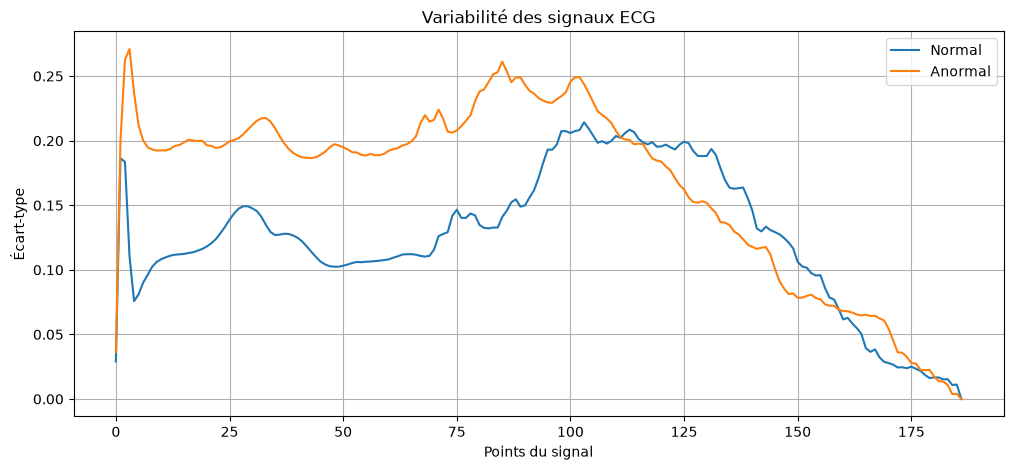

In [61]:
std_normal = normal.iloc[:, :-1].std()
std_anormal = abnormal.iloc[:, :-1].std()

plt.figure(figsize=(12, 5))

plt.plot(std_normal.values, label="Normal")
plt.plot(std_anormal.values, label="Anormal")

plt.title("Variabilité des signaux ECG")
plt.xlabel("Points du signal")
plt.ylabel("Écart-type")
plt.legend()
plt.grid(True)
plt.show()

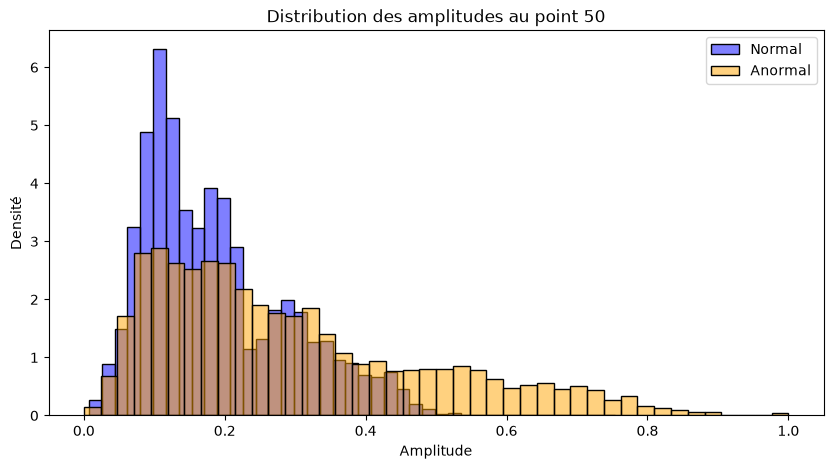

In [62]:
plt.figure(figsize=(10, 5))

sns.histplot(normal.iloc[:, 50], label="Normal",
             color="blue", alpha=0.5, stat="density")

sns.histplot(abnormal.iloc[:, 50], label="Anormal",
             color="orange", alpha=0.5, stat="density")

plt.title("Distribution des amplitudes au point 50")
plt.xlabel("Amplitude")
plt.ylabel("Densité")
plt.legend()
plt.show()

### Analyse des distributions des amplitudes ECG

L'analyse des amplitudes au point 50 révèle des différences entre les distributions des battements normaux et anormaux.

Les battements normaux présentent une concentration importante autour des faibles amplitudes, tandis que les battements anormaux possèdent une distribution plus étalée vers les amplitudes élevées.

Cependant, un chevauchement important existe entre les deux classes, ce qui suggère qu'une seule caractéristique ne suffit probablement pas à les distinguer efficacement.

Ces observations motivent l'utilisation de modèles de classification exploitant simultanément plusieurs caractéristiques du signal ECG.